In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns

### Data Understanding

In [3]:
df = pd.read_csv('../data/raw/customer_churn_dataset.csv')

In [4]:
df.head()

,Customer_ID,Age,Gender,Location,Tenure_Months,Monthly_Charges,Total_Charges,Subscription_Type,Payment_Method,Login_Frequency,Support_Tickets,Complaints,Discount_Received,Contract_Type,Last_Login_Days,Usage_Hours,Customer_Satisfaction,Churn
0,CUST104939,27.0,Female,Ahmedabad,12,1106.24,12694.02,Premium,Debit Card,16,1,0,0,Month-to-Month,10,46.7,4.0,0
1,CUST108673,52.0,Male,Hyderabad,17,621.18,62.12,Standard,UPI,13,1,1,20,Month-to-Month,12,45.4,5.0,0
2,CUST103277,18.0,Male,?,31,297.43,9149.23,Basic,UPI,14,3,1,5,Month-to-Month,11,19.4,4.0,1
3,CUST105552,45.0,Other,Kolkata,26,594.26,14894.33,Standard,UPI,6,4,3,0,Month-to-Month,8,NaN,1.0,0
4,CUST108857,49.0,Female,Mumbai,28,570.39,15385.08,Standard,Debit Card,10,0,0,5,One Year,23,26.4,4.0,0


- Records and Features

In [5]:
df.shape # (rows, columns)

(10070, 18)

In [6]:
df.columns.tolist()

['Customer_ID',
 'Age',
 'Gender',
 'Location',
 'Tenure_Months',
 'Monthly_Charges',
 'Total_Charges',
 'Subscription_Type',
 'Payment_Method',
 'Login_Frequency',
 'Support_Tickets',
 'Complaints',
 'Discount_Received',
 'Contract_Type',
 'Last_Login_Days',
 'Usage_Hours',
 'Customer_Satisfaction',
 'Churn']

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10070 entries, 0 to 10069
Data columns (total 18 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Customer_ID            10070 non-null  str    
 1   Age                    9060 non-null   str    
 2   Gender                 10070 non-null  str    
 3   Location               10070 non-null  str    
 4   Tenure_Months          10070 non-null  int64  
 5   Monthly_Charges        10070 non-null  float64
 6   Total_Charges          9103 non-null   str    
 7   Subscription_Type      10070 non-null  str    
 8   Payment_Method         9971 non-null   str    
 9   Login_Frequency        10070 non-null  int64  
 10  Support_Tickets        10070 non-null  int64  
 11  Complaints             10070 non-null  int64  
 12  Discount_Received      10070 non-null  int64  
 13  Contract_Type          10070 non-null  str    
 14  Last_Login_Days        10070 non-null  int64  
 15  Usage_Hours  

- Numerical columns vs Categorical columns

In [8]:
nums_cols = df.select_dtypes(include='number').columns.tolist()
cal_cols = df.select_dtypes(exclude='number').columns.tolist()

In [9]:
print(nums_cols)
print(cal_cols)

['Tenure_Months', 'Monthly_Charges', 'Login_Frequency', 'Support_Tickets', 'Complaints', 'Discount_Received', 'Last_Login_Days', 'Usage_Hours', 'Customer_Satisfaction', 'Churn']
['Customer_ID', 'Age', 'Gender', 'Location', 'Total_Charges', 'Subscription_Type', 'Payment_Method', 'Contract_Type']


- Target variable

In [10]:
df['Churn'].value_counts()

Churn
0    8472
1    1598
Name: count, dtype: int64

In [11]:
df['Churn'].value_counts(normalize=True)

Churn
0    0.841311
1    0.158689
Name: proportion, dtype: float64

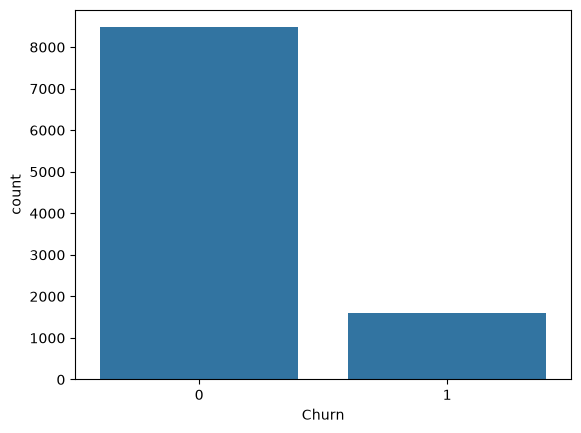

In [12]:
sns.countplot(x="Churn", data=df)
plt.show()

- Missing values

In [13]:
df.isna().sum().sort_values(ascending=False)

Age                      1010
Usage_Hours              1008
Customer_Satisfaction    1006
Total_Charges             967
Payment_Method             99
Customer_ID                 0
Monthly_Charges             0
Tenure_Months               0
Gender                      0
Location                    0
Login_Frequency             0
Subscription_Type           0
Support_Tickets             0
Complaints                  0
Contract_Type               0
Discount_Received           0
Last_Login_Days             0
Churn                       0
dtype: int64

In [14]:
# in percentage
(df.isna().mean() * 100).round(2)

Customer_ID               0.00
Age                      10.03
Gender                    0.00
Location                  0.00
Tenure_Months             0.00
Monthly_Charges           0.00
Total_Charges             9.60
Subscription_Type         0.00
Payment_Method            0.98
Login_Frequency           0.00
Support_Tickets           0.00
Complaints                0.00
Discount_Received         0.00
Contract_Type             0.00
Last_Login_Days           0.00
Usage_Hours              10.01
Customer_Satisfaction     9.99
Churn                     0.00
dtype: float64

In [15]:
# hidden missing values
df.isin(["", " ", "?", "N/A", "Unknown", -1]).sum()

Customer_ID                0
Age                        0
Gender                    92
Location                  96
Tenure_Months              0
Monthly_Charges            0
Total_Charges            302
Subscription_Type          0
Payment_Method             0
Login_Frequency            0
Support_Tickets            0
Complaints                 0
Discount_Received          0
Contract_Type              0
Last_Login_Days          100
Usage_Hours                0
Customer_Satisfaction      0
Churn                      0
dtype: int64

- Duplicates

In [16]:
print(df.duplicated().sum())       # duplicated rows

60


In [17]:
print(df['Customer_ID'].duplicated().sum())     # repeated ids

70


In [18]:
df[df["Customer_ID"].duplicated(keep=False)].sort_values("Customer_ID").head(10)

,Customer_ID,Age,Gender,Location,Tenure_Months,Monthly_Charges,Total_Charges,Subscription_Type,Payment_Method,Login_Frequency,Support_Tickets,Complaints,Discount_Received,Contract_Type,Last_Login_Days,Usage_Hours,Customer_Satisfaction,Churn
22,CUST100052,21.0,Female,Kolkata,35,340.07,"₹11,847.74",Basic,Credit Card,9,0,0,20,One Year,1,7.1,5.0,0
6657,CUST100052,21.0,Female,Kolkata,35,340.07,"₹11,847.74",Basic,Credit Card,9,0,0,20,One Year,1,7.1,5.0,0
159,CUST100270,29.0,Female,Chennai,8,318.73,2381.44,Basic,UPI,8,1,1,5,Month-to-Month,3,18.6,4.0,0
7840,CUST100270,29.0,Female,Chennai,8,318.73,2381.44,Basic,UPI,8,1,1,5,Month-to-Month,3,18.6,4.0,0
8327,CUST100403,NaN,Female,MUMBAI,32,338.03,10582.84,Basic,Credit Card,14,2,0,10,Month-to-Month,2,26.8,4.0,0
110,CUST100403,NaN,Female,MUMBAI,32,338.03,10582.84,Basic,Credit Card,14,2,0,10,Month-to-Month,2,26.8,4.0,0
7518,CUST100415,40.0,Male,Mumbai,17,326.70,5325.48,Basic,upi,11,2,1,0,Month-to-Month,7,62.3,4.0,0
2134,CUST100415,40.0,Male,Mumbai,17,326.70,5325.48,Basic,upi,11,1,1,0,Month-to-Month,7,62.3,4.0,0
6429,CUST100507,43.0,Female,AHMEDABAD,6,303.01,1689.95,Basic,UPI,14,2,1,5,One Year,2,19.8,NaN,0
41,CUST100507,43.0,Female,AHMEDABAD,6,303.01,1689.95,Basic,UPI,14,2,1,5,One Year,2,19.8,NaN,0


- Outliers

In [19]:
df.head()

,Customer_ID,Age,Gender,Location,Tenure_Months,Monthly_Charges,Total_Charges,Subscription_Type,Payment_Method,Login_Frequency,Support_Tickets,Complaints,Discount_Received,Contract_Type,Last_Login_Days,Usage_Hours,Customer_Satisfaction,Churn
0,CUST104939,27.0,Female,Ahmedabad,12,1106.24,12694.02,Premium,Debit Card,16,1,0,0,Month-to-Month,10,46.7,4.0,0
1,CUST108673,52.0,Male,Hyderabad,17,621.18,62.12,Standard,UPI,13,1,1,20,Month-to-Month,12,45.4,5.0,0
2,CUST103277,18.0,Male,?,31,297.43,9149.23,Basic,UPI,14,3,1,5,Month-to-Month,11,19.4,4.0,1
3,CUST105552,45.0,Other,Kolkata,26,594.26,14894.33,Standard,UPI,6,4,3,0,Month-to-Month,8,NaN,1.0,0
4,CUST108857,49.0,Female,Mumbai,28,570.39,15385.08,Standard,Debit Card,10,0,0,5,One Year,23,26.4,4.0,0


In [20]:
temp = df.copy()

for c in ['Age', 'Total_Charges']:
    temp[c] = pd.to_numeric(
        temp[c].astype(str).str.replace("₹", "").str.replace(",", ""),
        errors="coerce"
    )

temp.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,9029.0,38.374239,15.632955,-5.00,30.0000,38.00,46.00,999.00
Tenure_Months,10070.0,30.120258,19.498742,-3.00,16.0000,26.00,41.00,500.00
Monthly_Charges,10070.0,613.425506,1359.463972,-599.00,315.7225,579.06,677.02,59900.00
Total_Charges,8801.0,16475.047017,13716.050978,27.05,6774.9300,12468.29,21818.61,80425.04
Login_Frequency,10070.0,12.901887,3.822705,0.00,10.0000,13.00,15.00,28.00
Support_Tickets,10070.0,1.499007,1.496561,-2.00,1.0000,1.00,2.00,40.00
Complaints,10070.0,0.755909,0.920627,0.00,0.0000,1.00,1.00,7.00
Discount_Received,10070.0,7.063059,8.127161,-10.00,0.0000,5.00,15.00,100.00
Last_Login_Days,10070.0,8.798411,8.857580,-1.00,2.0000,6.00,12.00,92.00
Usage_Hours,9062.0,22.352317,30.023383,-10.00,11.7000,18.90,28.90,2400.00


In [21]:
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75])
    i = q3 - q1
    return ((s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)).sum()

for c in temp.select_dtypes("number").columns.drop("Churn"):
    print(c, iqr_outliers(temp[c]))

Age 51
Tenure_Months 6
Monthly_Charges 10
Total_Charges 424
Login_Frequency 98
Support_Tickets 635
Complaints 512
Discount_Received 4
Last_Login_Days 431
Usage_Hours 284
Customer_Satisfaction 51


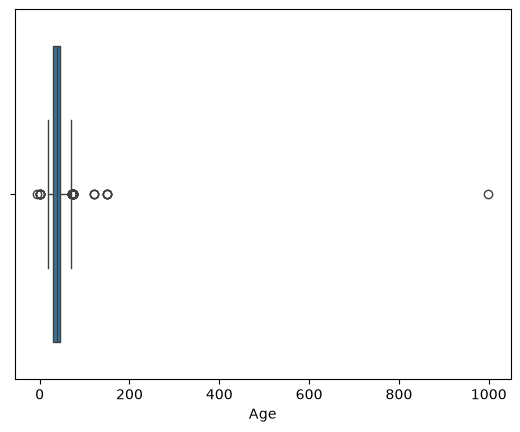

In [22]:
sns.boxplot(x=temp["Age"]) 
plt.show()

- Which features could influence churn ?

In [23]:
# Categorical features: churn rate per group
for c in ["Contract_Type", "Subscription_Type", "Payment_Method", "Gender", "Location"]:
    print(df.groupby(c)["Churn"].mean().sort_values(), "\n")

Contract_Type
two year            0.000000
TWO YEAR            0.000000
 Two Year           0.032258
Two Year            0.044099
one year            0.062500
 One Year           0.074627
ONE YEAR            0.081967
2 Year              0.083333
One Year            0.101918
1 Year              0.140000
 Month-to-Month     0.148515
month-to-month      0.196970
MONTH-TO-MONTH      0.222222
Month-to-Month      0.225603
Month to Month      0.270270
Name: Churn, dtype: float64 

Subscription_Type
standard      0.090909
 Standard     0.102564
 Basic        0.131148
Basic         0.139937
BASIC         0.145455
Standard      0.162379
basic         0.169492
PREMIUM       0.171429
premium       0.175000
Premium       0.185326
STANDARD      0.192982
 Premium      0.333333
Name: Churn, dtype: float64 

Payment_Method
 N/A             0.000000
 Debit Card      0.058824
upi              0.075758
NetBanking       0.100000
Upi              0.129032
NET BANKING      0.136364
 Wallet          0.142857


In [24]:
# Numeric features: average value for churned vs retained customers
temp.groupby("Churn")[["Tenure_Months", "Last_Login_Days", "Login_Frequency", "Complaints", "Customer_Satisfaction", "Monthly_Charges"]].mean()

,Tenure_Months,Last_Login_Days,Login_Frequency,Complaints,Customer_Satisfaction,Monthly_Charges
Churn,,,,,,
0,31.238314,8.375826,13.061261,0.678234,3.738413,606.531288
1,24.192741,11.038798,12.056946,1.167710,3.341515,649.976083


In [25]:
# Correlation with churn
temp.select_dtypes("number").corr()["Churn"].sort_values()

Customer_Satisfaction   -0.183604
Tenure_Months           -0.132033
Login_Frequency         -0.096000
Total_Charges           -0.078963
Discount_Received       -0.053400
Usage_Hours             -0.018090
Monthly_Charges          0.011677
Age                      0.015312
Support_Tickets          0.101810
Last_Login_Days          0.109856
Complaints               0.194277
Churn                    1.000000
Name: Churn, dtype: float64

### Data Cleaning

In [26]:
# standardising the text
categorial_col = ["Gender", "Location", "Subscription_Type", "Payment_Method", "Contract_Type"]
placeholders = ["", "?", "n/a", "na", "unknown", "none", "nan"]

for c in categorial_col:
    s = temp[c].astype("string").str.strip()
    s = s.where(~s.str.lower().isin(placeholders), pd.NA)
    temp[c] = s.str.title()

temp["Gender"] = temp["Gender"].replace({"M": "Male", "F": "Female"})

temp["Location"] = temp["Location"].replace({"Bangalore": "Bengaluru", "Bombay": "Mumbai", "Calcutta": "Kolkata"})

temp["Payment_Method"] = temp["Payment_Method"].replace(
    {"Creditcard": "Credit Card", "Debit": "Debit Card", "Netbanking": "Net Banking", "Upi": "UPI"}
)

temp["Contract_Type"] = temp["Contract_Type"].replace(
    {"Month To Month": "Month-to-Month", "1 Year": "One Year", "2 Year": "Two Year"}
)

In [27]:
temp.head()

,Customer_ID,Age,Gender,Location,Tenure_Months,Monthly_Charges,Total_Charges,Subscription_Type,Payment_Method,Login_Frequency,Support_Tickets,Complaints,Discount_Received,Contract_Type,Last_Login_Days,Usage_Hours,Customer_Satisfaction,Churn
0,CUST104939,27.0,Female,Ahmedabad,12,1106.24,12694.02,Premium,Debit Card,16,1,0,0,Month-To-Month,10,46.7,4.0,0
1,CUST108673,52.0,Male,Hyderabad,17,621.18,62.12,Standard,UPI,13,1,1,20,Month-To-Month,12,45.4,5.0,0
2,CUST103277,18.0,Male,<NA>,31,297.43,9149.23,Basic,UPI,14,3,1,5,Month-To-Month,11,19.4,4.0,1
3,CUST105552,45.0,Other,Kolkata,26,594.26,14894.33,Standard,UPI,6,4,3,0,Month-To-Month,8,NaN,1.0,0
4,CUST108857,49.0,Female,Mumbai,28,570.39,15385.08,Standard,Debit Card,10,0,0,5,One Year,23,26.4,4.0,0


In [28]:
# Fixing the data types
def to_num(s):
    s = s.astype('string') \
            .str.replace("₹", "", regex=False)\
            .str.replace(",", "", regex=False)\
            .str.strip()
    return pd.to_numeric(s, errors='coerce')

for c in ['Age', 'Total_Charges']:
    temp[c] = to_num(temp[c])

In [29]:
temp.info()

<class 'pandas.DataFrame'>
RangeIndex: 10070 entries, 0 to 10069
Data columns (total 18 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Customer_ID            10070 non-null  str    
 1   Age                    9029 non-null   Float64
 2   Gender                 9969 non-null   string 
 3   Location               9970 non-null   string 
 4   Tenure_Months          10070 non-null  int64  
 5   Monthly_Charges        10070 non-null  float64
 6   Total_Charges          8801 non-null   Float64
 7   Subscription_Type      10070 non-null  string 
 8   Payment_Method         9969 non-null   string 
 9   Login_Frequency        10070 non-null  int64  
 10  Support_Tickets        10070 non-null  int64  
 11  Complaints             10070 non-null  int64  
 12  Discount_Received      10070 non-null  int64  
 13  Contract_Type          10070 non-null  string 
 14  Last_Login_Days        10070 non-null  int64  
 15  Usage_Hours  

In [30]:
# Fix invalid values --> (NAN)
cols = {
    "Age": (18, 100),
    "Tenure_Months": (1, 120),
    "Monthly_Charges": (100, 2000),
    "Usage_Hours": (0, 300),            # ~10 h/day is already extreme
    "Customer_Satisfaction": (1, 5),
    "Support_Tickets": (0, 30),
    "Discount_Received": (0, 50),
    "Login_Frequency": (0, 100),
    "Last_Login_Days": (0, 365),        # also catches the -1 placeholder
    "Complaints": (0, 30),
}

for c, (lo, hi) in cols.items():
    bad = (temp[c] < lo) | (temp[c] > hi)
    print(f"invalid {c}={int(bad.sum())}")
    temp.loc[bad, c] = np.nan

invalid Age=15
invalid Tenure_Months=12
invalid Monthly_Charges=12
invalid Usage_Hours=9
invalid Customer_Satisfaction=20
invalid Support_Tickets=8
invalid Discount_Received=10
invalid Login_Frequency=0
invalid Last_Login_Days=100
invalid Complaints=0


In [31]:
# Fixing duplicates
print(f"exact duplicate rows: {int(temp.duplicated().sum())}")

temp = temp.drop_duplicates()
temp["_missing"] = temp.isna().sum(axis=1)

print(
    f"repeated Customer_ID after exact-dedup: {int(temp["Customer_ID"].duplicated().sum())}"
)

temp = (temp.sort_values(["Customer_ID", "_missing"])       # keep the most complete record
            .drop_duplicates("Customer_ID", keep="first")
            .drop(columns="_missing")
            .sort_values("Customer_ID").reset_index(drop=True))

exact duplicate rows: 60
repeated Customer_ID after exact-dedup: 10


In [32]:
# handling missing values
print(f"missing before imputation = {temp.isna().sum()[temp.isna().sum() > 0].to_dict()}")

# categorical -> mode
for c in categorial_col:
    temp[c] = temp[c].fillna(temp[c].mode()[0])
 
# business-based: price follows the plan
temp["Monthly_Charges"] = temp["Monthly_Charges"].fillna(
    temp.groupby("Subscription_Type")["Monthly_Charges"].transform("median")
)

# numeric -> median (robust to outliers)
for c in ["Age", "Tenure_Months", "Usage_Hours", "Login_Frequency", "Last_Login_Days", "Support_Tickets", "Discount_Received", "Complaints"]:
    temp[c] = temp[c].fillna(temp[c].median())
 
# satisfaction is an ordinal 1-5 score -> mode
temp["Customer_Satisfaction"] = temp["Customer_Satisfaction"].fillna(temp["Customer_Satisfaction"].mode()[0])
 
# business-based: Total ~ Monthly x Tenure (original data averaged ~96%)
expected = temp["Monthly_Charges"] * temp["Tenure_Months"]
ratio = temp["Total_Charges"] / expected
illogical = (ratio < 0.5) | (ratio > 1.1)

print(f"illogical Total_Charges = {int(illogical.sum())}")

temp.loc[illogical, "Total_Charges"] = np.nan
temp["Total_Charges"] = temp["Total_Charges"].fillna((expected * 0.96).round(2))

missing before imputation = {'Age': 1046, 'Gender': 100, 'Location': 100, 'Tenure_Months': 12, 'Monthly_Charges': 12, 'Total_Charges': 1261, 'Payment_Method': 100, 'Support_Tickets': 8, 'Discount_Received': 10, 'Last_Login_Days': 100, 'Usage_Hours': 1007, 'Customer_Satisfaction': 1019}
illogical Total_Charges = 102


In [33]:
temp.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 18 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Customer_ID            10000 non-null  str    
 1   Age                    10000 non-null  Float64
 2   Gender                 10000 non-null  string 
 3   Location               10000 non-null  string 
 4   Tenure_Months          10000 non-null  float64
 5   Monthly_Charges        10000 non-null  float64
 6   Total_Charges          10000 non-null  Float64
 7   Subscription_Type      10000 non-null  string 
 8   Payment_Method         10000 non-null  string 
 9   Login_Frequency        10000 non-null  float64
 10  Support_Tickets        10000 non-null  float64
 11  Complaints             10000 non-null  float64
 12  Discount_Received      10000 non-null  float64
 13  Contract_Type          10000 non-null  string 
 14  Last_Login_Days        10000 non-null  float64
 15  Usage_Hours   

In [34]:
temp.head()

,Customer_ID,Age,Gender,Location,Tenure_Months,Monthly_Charges,Total_Charges,Subscription_Type,Payment_Method,Login_Frequency,Support_Tickets,Complaints,Discount_Received,Contract_Type,Last_Login_Days,Usage_Hours,Customer_Satisfaction,Churn
0,CUST100000,42.0,Female,Delhi,16.0,1148.12,18313.89,Premium,Credit Card,14.0,4.0,2.0,0.0,One Year,22.0,47.5,2.0,1
1,CUST100001,26.0,Male,Hyderabad,31.0,331.28,9858.89,Basic,Debit Card,17.0,2.0,1.0,0.0,Two Year,6.0,26.3,4.0,0
2,CUST100002,47.0,Female,Bengaluru,28.0,1107.48,28768.6,Premium,Net Banking,17.0,1.0,0.0,0.0,One Year,1.0,39.7,4.0,0
3,CUST100003,49.0,Male,Ahmedabad,26.0,953.48,24395.43,Premium,UPI,21.0,0.0,0.0,10.0,Two Year,21.0,29.8,5.0,0
4,CUST100004,18.0,Male,Kolkata,29.0,601.22,16855.35,Standard,Debit Card,10.0,1.0,0.0,0.0,One Year,6.0,15.3,4.0,0


In [35]:
# final types fixing
for c in ["Age", "Tenure_Months", "Login_Frequency", "Last_Login_Days", "Support_Tickets", "Complaints", "Discount_Received", "Customer_Satisfaction", "Churn"]:
    temp[c] = temp[c].round().astype(int)

temp.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 18 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Customer_ID            10000 non-null  str    
 1   Age                    10000 non-null  int64  
 2   Gender                 10000 non-null  string 
 3   Location               10000 non-null  string 
 4   Tenure_Months          10000 non-null  int64  
 5   Monthly_Charges        10000 non-null  float64
 6   Total_Charges          10000 non-null  Float64
 7   Subscription_Type      10000 non-null  string 
 8   Payment_Method         10000 non-null  string 
 9   Login_Frequency        10000 non-null  int64  
 10  Support_Tickets        10000 non-null  int64  
 11  Complaints             10000 non-null  int64  
 12  Discount_Received      10000 non-null  int64  
 13  Contract_Type          10000 non-null  string 
 14  Last_Login_Days        10000 non-null  int64  
 15  Usage_Hours   

In [36]:
# Update the changes in the df
df = temp
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 18 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Customer_ID            10000 non-null  str    
 1   Age                    10000 non-null  int64  
 2   Gender                 10000 non-null  string 
 3   Location               10000 non-null  string 
 4   Tenure_Months          10000 non-null  int64  
 5   Monthly_Charges        10000 non-null  float64
 6   Total_Charges          10000 non-null  Float64
 7   Subscription_Type      10000 non-null  string 
 8   Payment_Method         10000 non-null  string 
 9   Login_Frequency        10000 non-null  int64  
 10  Support_Tickets        10000 non-null  int64  
 11  Complaints             10000 non-null  int64  
 12  Discount_Received      10000 non-null  int64  
 13  Contract_Type          10000 non-null  string 
 14  Last_Login_Days        10000 non-null  int64  
 15  Usage_Hours   

In [38]:
df.to_csv("../data/processed/customer_churn_clean.csv", index=False)

### Exploratory Data Analysis